## Assignment 04: Communication Protocols


<div class="alert alert-light">

  **Name:** Suleman Ali Khan
  
  **Matriculation Number:** 21-715-917
  
</div>



The submission deadline is <span style="background-color:rgba(0, 150, 255, 0.5); padding:2px 4px; border-radius:3px;">Monday, 2026-Oct-19 (23:59)</span>.
Students <span style="background-color:rgba(255, 123, 0, 0.5); padding:2px 4px; border-radius:3px;">must work alone</span> and provide their own results. 

Fill in your responses below in the marked blocks. The expected length of each answer is provided in each block.

- (S) Short, 1–2 sentences (~20–40 words). *A quick factual or definition-style answer.*
- (M) Medium, 3–8 sentences (~60–120 words). *Brief explanation with reasoning or an example.*
- (L) Long, multi-paragraph (150–300 words). *Detailed discussion, include reasoning, examples, and context.*
- (V) Visualizations and graphs. *Include plots or figures that illustrate your results.*
- (E) Statistical evaluation and information. *Provide numeric context such as mean, variance, random seed used, confidence intervals, etc.*

Save this notebook and upload the modified file to Moodle.

The motivation for this assignment is to understand how data is encoded, transmitted, and made reliable through communication protocols by exploring entropy, compression, access control, and multipath handling, and to connect theoretical principles with practical signal and protocol behavior.

---

## Questions



### Step 1: Data Entropy & Encoding (2 points)

1) Open [`Data_Entropy.ipynb`](../../notebooks/02%20Data%20And%20Signals/Data_Entropy.ipynb) and set $m=n=40$. Which of the three matrices has the highest entropy and why?

<div class="alert alert-info">

(S) Answer: The random matrix has the highest entropy because its 0s and 1s are most uniformly distributed and least predictable. The all-ones matrix has zero entropy, and the patterned matrix contains repeated structure, so both are more predictable than the random matrix.

2) If a data source has entropy close to zero, what does that mean for the information content and transmission efficiency in a network?

<div class="alert alert-info">

(S) Answer: Low entropy means the source is highly predictable and contains little new information. As a result, it can be transmitted or compressed very efficiently because fewer bits are needed to represent the data.

3) Open [`Data_Compression.ipynb`](../../notebooks/02%20Data%20And%20Signals/Data_Compression.ipynb). If all characters in a text occur with the same frequency, what happens to the compression efficiency of Huffman coding?

<div class="alert alert-info">

(M) Answer: If all characters occur with the same frequency, Huffman coding has very little compression advantage. Since there is no significant difference in symbol probabilities, the algorithm cannot assign much shorter codes to frequent symbols, so the code lengths become nearly equal and the compression ratio approaches that of fixed-length encoding.

4. What problem is prevented by Huffman codes being prefix-free?

<div class="alert alert-info">

(S) Answer: Prefix-free Huffman codes prevent ambiguity during decoding. Because no code is a prefix of another, the receiver can always determine where one symbol ends and the next one begins without needing separators or backtracking.

5. Why might a mobile device choose a lower compression ratio even if stronger compression saves bandwidth? Explain the trade-offs for small and efficient devices.

<div class="alert alert-info">

(M) Answer: A mobile device may choose less aggressive compression to reduce processing time and energy use, which is especially important when its processor, memory, or battery is limited. Stronger compression can save bandwidth, but may require more computation and, for lossy methods, reduce image or audio quality. The device therefore balances bandwidth savings against battery life, processing cost, latency, and acceptable quality.

### Step 2: Protocols for Reliability (3 points)

1) Open [`Protocol_ARQ.ipynb`](../../notebooks/03%20Wireless%20Foundations/Protocol_ARQ.ipynb) and initially set $\text{NUM\_PACKETS} = 30000$ and $\text{WINDOW\_SIZE} = 8$. Describe the difference between Stop-and-Wait ARQ, Go-Back-N ARQ, and Selective Repeat ARQ.

<div class="alert alert-info">

(M) Answer: Stop-and-Wait sends one packet and waits for its acknowledgment before sending the next; if the packet is lost or corrupted, it is retransmitted after a timeout. Go-Back-N allows multiple packets to be sent within a window, but when a packet is lost, the sender retransmits that packet and the subsequent packets in the window. Selective Repeat also allows multiple packets in flight, but acknowledges them individually and retransmits only the missing or corrupted packets.

2) Increase $\text{WINDOW\_SIZE} = 16$. Provide visualizations for both values and interpret the results.

<div class="alert alert-info">

(V, M) Answer: 

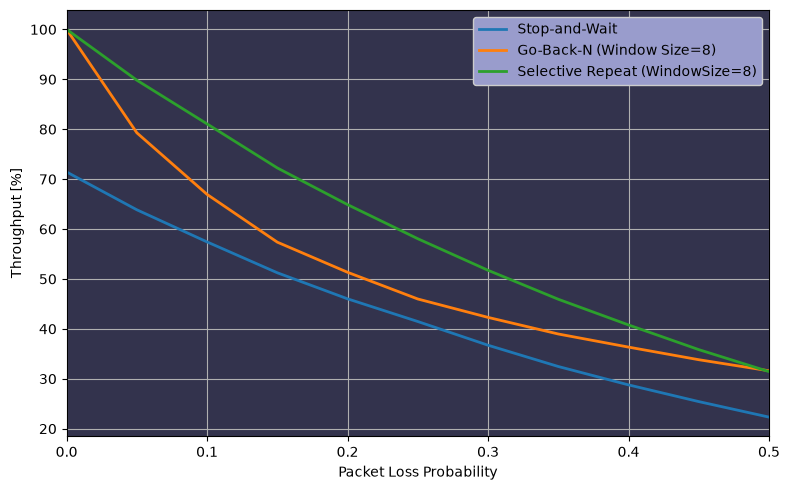
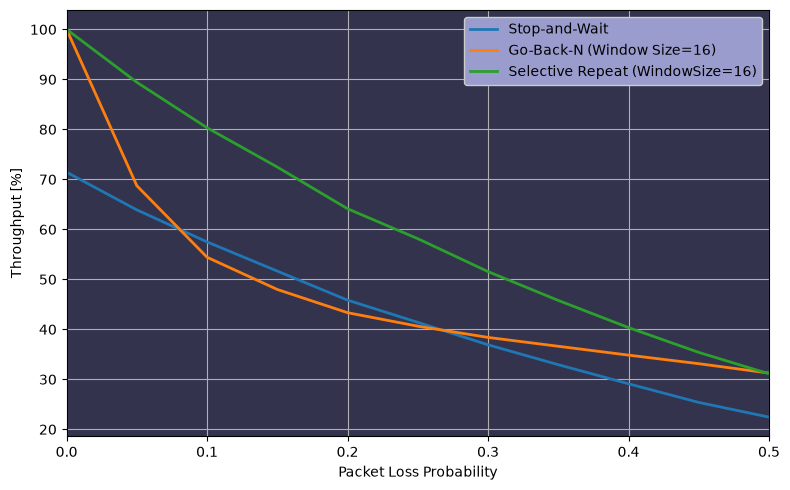

Stop-and-Wait is unaffected by the window size because it sends only one packet at a time. Increasing the window can improve Go-Back-N and Selective Repeat by allowing more packets to be in flight simultaneously. However, when losses occur, Go-Back-N may need to retransmit several packets after a loss, whereas Selective Repeat retransmits only the missing packets. This makes Selective Repeat more efficient when losses are frequent, although its performance is still affected by packet loss.

3) Open [`Protocol_AccessControl.ipynb`](../../notebooks/03%20Wireless%20Foundations/Protocol_AccessControl.ipynb). What are the general trends for the throughput performance (per station and per network) and the delay performance (per station and per network), with an increasing number of transmitting radio stations that operate at the same time? Take CSMA/CA or ALOHA protocols into consideration.

<div class="alert alert-info">

(M) Answer: As the number of transmitting stations increases, each station gets a smaller share of the channel, so its average throughput generally decreases. Aggregate network throughput may initially rise as more stations offer traffic, but it eventually levels off or can fall as collisions and retransmissions consume more airtime. ALOHA is especially vulnerable to collisions; CSMA/CA reduces them by sensing the channel, but contention and backoff still increase delay as more stations compete. Thus, both per-station and overall delay generally increase under heavier contention.

4) What is the main cost of introducing time slots in Slotted ALOHA?

<div class="alert alert-info">

(S) Answer: The main cost is that all stations must synchronize their clocks so they transmit only at slot boundaries. This synchronization adds system complexity and overhead.

5) Why is collision detection (CSMA/CD) not used in wireless communication?

<div class="alert alert-info">

(S) Answer: Wireless devices generally cannot detect a collision while transmitting because their own transmitted signal overwhelms weaker signals from other devices. They therefore use collision avoidance (CSMA/CA) rather than collision detection (CSMA/CD).

6) Generate and provide the comparison plot of Aloha and CSMA. Explain the performance of the different protocol approaches with the help of this graph.

<div class="alert alert-info">

(V, L) Answer: 

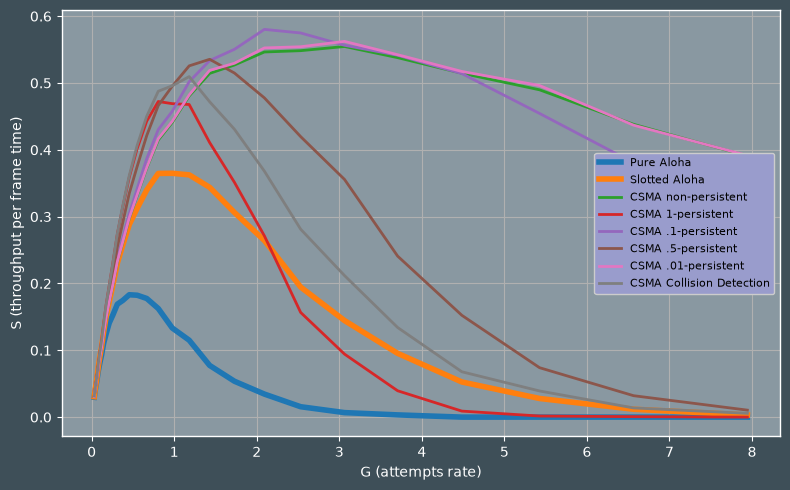

The plot shows that Pure ALOHA achieves the lowest throughput, peaking at about 0.18, while Slotted ALOHA peaks at about 0.36. These are close to their theoretical maximum throughputs of 18.4% and 36.8%, respectively. CSMA variants generally achieve higher peak throughput because sensing the channel reduces collisions. However, throughput depends on both the offered load and the persistence strategy: 1-persistent CSMA performs poorly at high loads, where many stations may transmit as soon as the channel becomes idle and collide. Lower-persistence and non-persistent CSMA reduce the likelihood of simultaneous transmissions and perform better over much of the higher-load range in this simulation, though waiting can leave the channel idle. All methods eventually lose throughput as offered load grows and collisions or contention increase. The graph’s peaks are simulation results, so they may vary with the random arrivals.

### Step 3: Multipath in Wireless Networks (3 points)

1) Open [`Channel_OFDM.ipynb`](../../notebooks/03%20Wireless%20Foundations/Channel_OFDM.ipynb). What problem does OFDM solve in wireless communication?

<div class="alert alert-info">

(S) Answer: OFDM helps mitigate inter-symbol interference caused by multipath propagation. It divides a high-data-rate signal across many lower-rate, orthogonal subcarriers, making wireless communication more robust to delayed signal copies.

2) What does the term orthogonal mean in OFDM and what would happen if the subcarriers were not orthogonal?

<div class="alert alert-info">

(S) Answer: In OFDM, orthogonal means that over one symbol period, different subcarriers have zero cross-correlation, so the receiver can distinguish them even when their spectra overlap. If they were not orthogonal, they would interfere with one another, causing inter-carrier interference and increasing decoding errors.

3) Why do we divide a wideband signal into many subcarriers in OFDM?

<div class="alert alert-info">

(S) Answer: OFDM divides a wideband signal into many narrower subcarriers, each carrying data at a lower rate. This makes each subcarrier less susceptible to frequency-selective fading and multipath delay, reducing inter-symbol interference and simplifying equalization.

4) What is the purpose of the cyclic prefix (CP) and what trade-offs does it introduce?

<div class="alert alert-info">

(M) Answer: The cyclic prefix (CP) is a copy of the end of an OFDM symbol added to its beginning. It acts as a guard interval, reducing inter-symbol interference caused by multipath delays, provided it is long enough to cover the channel’s delay spread. The trade-off is that a longer CP adds overhead, reducing spectral efficiency and the effective data rate.

5) Generate and provide the impulse and frequency response diagrams. What does each plot represent?

<div class="alert alert-info">

(V, M) Answer: 

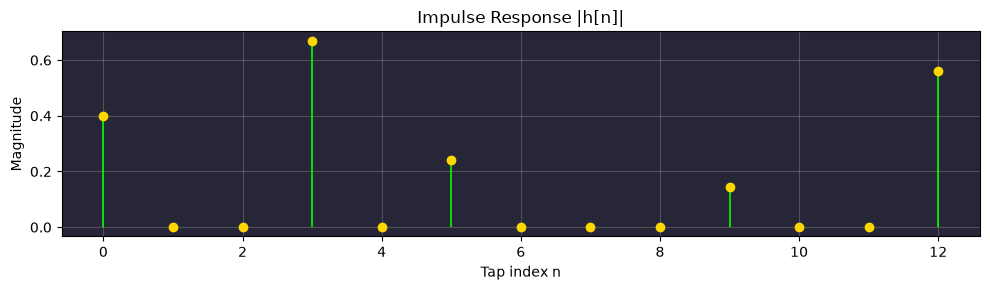
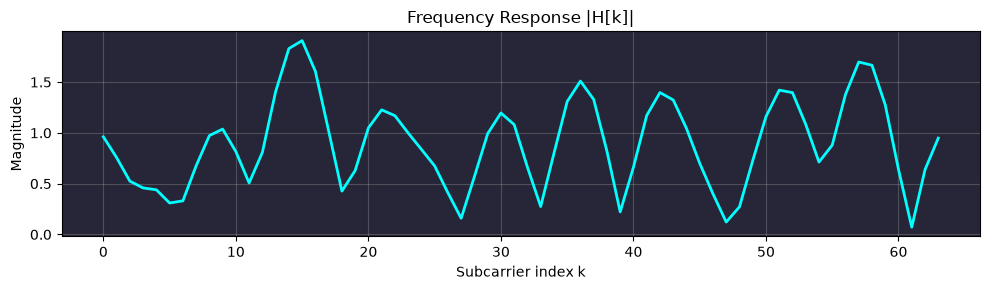

The impulse-response plot shows the channel’s multipath components: each tap represents a received signal path at a particular delay, and its magnitude indicates that path’s strength. The frequency-response plot shows the channel gain across the OFDM subcarriers. Its variations indicate frequency-selective fading, where some subcarriers are attenuated more than others.


6) Open [`Channel_MIMO.ipynb`](../../notebooks/03%20Wireless%20Foundations/Channel_MIMO.ipynb). What is the main idea behind MIMO?

<div class="alert alert-info">

(S) Answer: MIMO uses multiple transmit and receive antennas to exploit the different channel paths between them. This can create parallel spatial data streams to increase data rate, or improve reliability through diversity techniques.

7) How does MIMO turn multipath from a problem into an advantage?

<div class="alert alert-info">

(S) Answer: MIMO exploits the different channel paths between transmit and receive antennas to send independent data streams simultaneously using spatial multiplexing, increasing data rate. Alternatively, it can use those paths for diversity to improve reliability.

8) Generate and provide the MIMO signal transformation plot with zero-forcing. Interpret the results.

<div class="alert alert-info">

(V, M) Answer: 

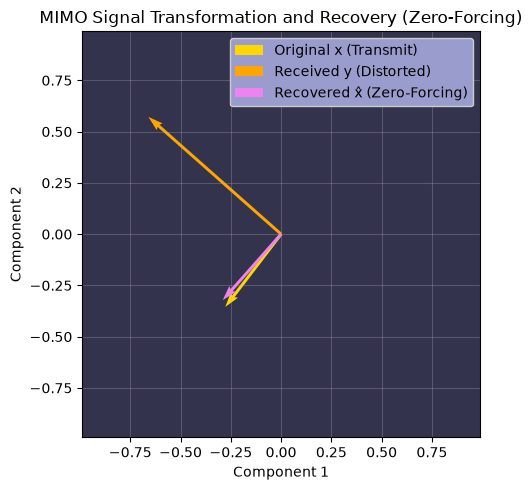

With zero-forcing equalization, the receiver uses knowledge of the channel matrix to undo the channel’s effects and estimate the transmitted signal. In the plot, the recovered signal $\hat{x}$ is close to the original (x), despite the distortion in the received signal (y). The estimate may not be exact because of noise, channel-estimation errors, or an ill-conditioned channel.

### Optional Feedback (not graded)

1. Did you read through and understand all the tasks in this assignment and the related notebooks? Are there any shortcomings, missing parts, or sections that should be improved? You can also give your feedback anonymously, through moodle. Please help the teaching team by telling us what part was not understood, and we will work on it in the future.

<div class="alert alert-info">

Optional Feedback, not graded: *(double click to edit)*